# UTS Graf Sains Data: Neo4j, Vector Space Model, dan Rekomendasi KNN

Nazril Ravi Pratama
24031554129
International 24
Graf Sains Data, S1 Sains Data, Universitas Negeri Surabaya 
RetailRocket e-commerce events (Kaggle)


## 0. Persiapan

In [1]:
import getpass
import inspect
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from src import config, data_prep, graph_io, metrics, queries, recommender, viz, vsm

pd.options.display.float_format = "{:,.4f}".format
pd.options.display.max_columns = 30
%matplotlib inline

print(f"{config.STUDENT['name']} | NIM {config.STUDENT['nim']} | {config.STUDENT['class']}")
print(f"Seed acak (NIM) : {config.SEED}")
print(f"Database target : {config.NEO4J_DATABASE} @ {config.NEO4J_URI}")

Nazril Ravi Pratama | NIM 24031554129 | International 24
Seed acak (NIM) : 24031554129
Database target : retailrocket @ bolt://127.0.0.1:7687


In [2]:
PASSWORD = os.environ.get("NEO4J_PASSWORD") or getpass.getpass(f"Password Neo4j untuk user '{config.NEO4J_USER}': ")
driver = graph_io.connect(config.NEO4J_URI, config.NEO4J_USER, PASSWORD)
DB = config.NEO4J_DATABASE
graph_io.ensure_database(driver, DB)
print("Terhubung ke Neo4j. Database kerja:", DB)

Terhubung ke Neo4j. Database kerja: retailrocket


## 1. Tugas Pendahuluan

### 1.1 Environment

### 1.2 Tutorial driver

In [3]:
from neo4j import RoutingControl

DEMO_DB = "neo4j"

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DEMO_DB,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DEMO_DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

for friend in ("Guinevere", "Lancelot", "Merlin"):
    add_friend(driver, "Arthur", friend)
print_friends(driver, "Arthur")

driver.execute_query(
    "MATCH (p:Person) WHERE p.name IN ['Arthur', 'Guinevere', 'Lancelot', 'Merlin'] DETACH DELETE p",
    database_=DEMO_DB,
)

Guinevere
Lancelot
Merlin


EagerResult(records=[], summary=<neo4j._work.summary.ResultSummary object at 0x000001EC333FD1D0>, keys=[])

The tutorial uses neo4j as the default database in an instance. To access other databases, we can use driver.session(database="name"), execute_query, or the :use command in Neo4j Browser, while database management is handled through the system database. The resulting graph is a directed graph with a single KNOWS relationship type, no weights, and a star graph structure with Arthur at the center, meaning the friendships are not symmetric. In the import process implemented in src/graph_io.py, a UNIQUE constraint prevents duplicate nodes. Nodes are created first, followed by relationships based on each event type. The database is also cleared before importing so the process can be repeated without creating duplicate relationships.

## 2. Soal UTS

## 2.1 Wrangling dan EDA

### No. 1: Periode waktu dan data mentah

Timestamp awal dan akhir dataset (untuk formulir) dicetak di sel berikut.

In [5]:
events = data_prep.load_events(config.RAW_EVENTS)

first_ts, last_ts = int(events["timestamp"].min()), int(events["timestamp"].max())
print("ISIAN FORMULIR  (UNIX timestamp sesuai dataset, satuan milidetik)")
print(f"  Periode dataset (mulai)  : {first_ts}")
print(f"  Periode dataset (selesai): {last_ts}")
print(f"  (dalam detik: {first_ts // 1000} dan {last_ts // 1000})")
print(f"  Setara tanggal UTC       : {events['datetime'].min():%Y-%m-%d %H:%M:%S} sampai {events['datetime'].max():%Y-%m-%d %H:%M:%S}")

ISIAN FORMULIR  (UNIX timestamp sesuai dataset, satuan milidetik)
  Periode dataset (mulai)  : 1430622004384
  Periode dataset (selesai): 1442545187788
  (dalam detik: 1430622004 dan 1442545187)
  Setara tanggal UTC       : 2015-05-03 03:00:04 sampai 2015-09-18 02:59:47


In [6]:
n_events, n_visitors, n_items = len(events), events["visitorid"].nunique(), events["itemid"].nunique()
mix = events["event"].value_counts()
cart_rate = mix["addtocart"] / mix["view"]
purchase_rate = mix["transaction"] / mix["addtocart"]

summary = pd.DataFrame(
    {"nilai": [n_events, n_visitors, n_items, mix["view"], mix["addtocart"], mix["transaction"]]},
    index=["total event", "visitor unik", "item unik", "event view", "event addtocart", "event transaction"],
)
display(summary.style.format("{:,.0f}"))

share_cart = events.loc[events["event"] == "addtocart", "visitorid"].nunique() / n_visitors
share_buy = events.loc[events["event"] == "transaction", "visitorid"].nunique() / n_visitors
print("INSIGHT")
print(f"- Dari {n_events:,} event, {mix['view'] / n_events:.1%} hanyalah view. Transaksi cuma {mix['transaction'] / n_events:.2%}.")
print(f"- Funnel tingkat event: view -> addtocart = {cart_rate:.1%}; addtocart -> transaction = {purchase_rate:.1%}.")
print(f"- Tingkat visitor: hanya {share_cart:.1%} visitor pernah menaruh barang di keranjang dan {share_buy:.1%} pernah membeli.")
print("  Artinya sinyal 'preferensi' hampir seluruhnya implisit (view), dan pembelian adalah sinyal yang langka tetapi sangat informatif.")
print(f"- Rata-rata {n_events / n_visitors:.1f} event per visitor dan {n_events / n_items:.1f} event per item.")

,nilai
total event,"2,756,101"
visitor unik,"1,407,580"
item unik,"235,061"
event view,"2,664,312"
event addtocart,"69,332"
event transaction,"22,457"


INSIGHT
- Dari 2,756,101 event, 96.7% hanyalah view. Transaksi cuma 0.81%.
- Funnel tingkat event: view -> addtocart = 2.6%; addtocart -> transaction = 32.4%.
- Tingkat visitor: hanya 2.7% visitor pernah menaruh barang di keranjang dan 0.8% pernah membeli.
  Artinya sinyal 'preferensi' hampir seluruhnya implisit (view), dan pembelian adalah sinyal yang langka tetapi sangat informatif.
- Rata-rata 2.0 event per visitor dan 11.7 event per item.


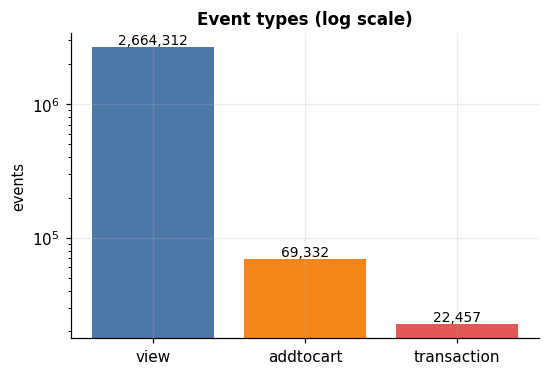

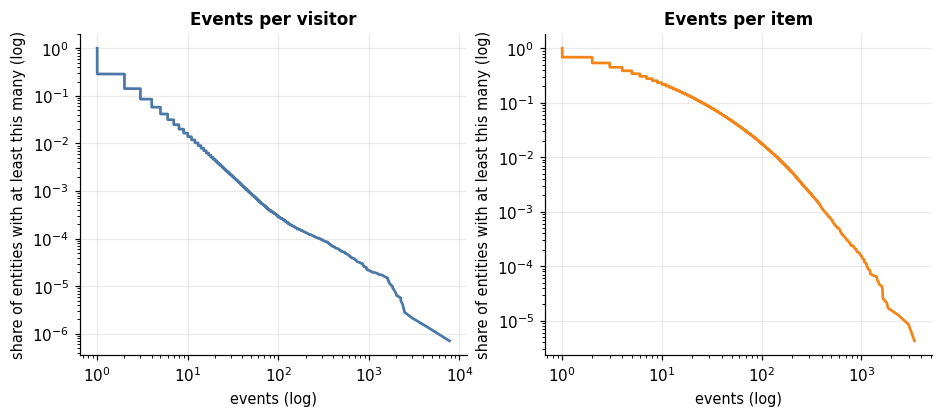

INSIGHT (ekor panjang)
- Median visitor hanya punya 1 event, tetapi visitor paling aktif punya 7,757 event.
- 1% visitor teratas menyumbang 17.5% seluruh event. Visitor semacam ini umumnya bot, crawler, atau akun toko, bukan pembeli biasa.
- Distribusi item juga timpang: median 3 event per item, maksimum 3,412.
- Konsekuensi: matriks interaksi akan sangat sparse, dan visitor 'super aktif' harus ditangani agar tidak mendominasi similarity.


In [7]:
viz.plot_event_mix(events)
plt.show()
viz.plot_ccdf(events)
plt.show()

per_visitor = events.groupby("visitorid").size()
per_item = events.groupby("itemid").size()
top1pct = per_visitor.nlargest(max(1, len(per_visitor) // 100)).sum() / n_events
print("INSIGHT (ekor panjang)")
print(f"- Median visitor hanya punya {per_visitor.median():.0f} event, tetapi visitor paling aktif punya {per_visitor.max():,} event.")
print(f"- 1% visitor teratas menyumbang {top1pct:.1%} seluruh event. Visitor semacam ini umumnya bot, crawler, atau akun toko, bukan pembeli biasa.")
print(f"- Distribusi item juga timpang: median {per_item.median():.0f} event per item, maksimum {per_item.max():,}.")
print("- Konsekuensi: matriks interaksi akan sangat sparse, dan visitor 'super aktif' harus ditangani agar tidak mendominasi similarity.")

pemilihan periodenya yaitu dibagi jadi two section P1 (training, 4 minggu) dan P2 (testing, 2 minggu) berdampingan, tidak tumpang tindih, dan P2 setelah P1 agar tidak ada *data leakage*. rules pembentukan periode diatur di src/config.py

P1 (training): 2015-06-15 00:00:00  ->  2015-07-12 23:59:59  (UTC)
P2 (testing) : 2015-07-13 00:00:00  ->  2015-07-26 23:59:59  (UTC)
Pemeriksaan: P1 dan P2 tidak tumpang tindih.


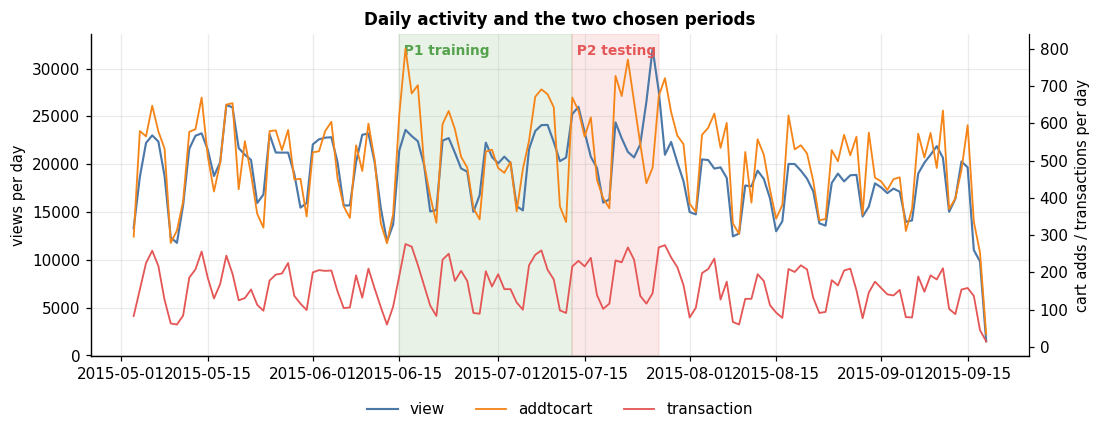

In [8]:
print(f"P1 (training): {config.PERIOD_P1[0]}  ->  {config.PERIOD_P1[1]}  (UTC)")
print(f"P2 (testing) : {config.PERIOD_P2[0]}  ->  {config.PERIOD_P2[1]}  (UTC)")
assert not data_prep.periods_overlap(config.PERIOD_P1, config.PERIOD_P2), "P1 dan P2 tidak boleh tumpang tindih"
print("Pemeriksaan: P1 dan P2 tidak tumpang tindih.")

viz.plot_timeline(events, config.PERIOD_P1, config.PERIOD_P2)
plt.show()

### No. 2: Filter timestamp dan simpan .csv

batas inklusifnya, satuan milidetik UTC. events_p1_train.csv dimuat ke Neo4j, events_p2_test.csv cuma jadi kunci jawaban evaluasi

In [9]:
train = data_prep.filter_period(events, config.PERIOD_P1)
test = data_prep.filter_period(events, config.PERIOD_P2)
data_prep.save_events(train, config.TRAIN_CSV)
data_prep.save_events(test, config.TEST_CSV)

report = pd.DataFrame(
    {
        "events": [len(train), len(test)],
        "visitors": [train["visitorid"].nunique(), test["visitorid"].nunique()],
        "items": [train["itemid"].nunique(), test["itemid"].nunique()],
        "share of all events": [len(train) / len(events), len(test) / len(events)],
    },
    index=["P1 train", "P2 test"],
)
display(report.style.format({"events": "{:,}", "visitors": "{:,}", "items": "{:,}", "share of all events": "{:.1%}"}))
print("Disimpan:", config.TRAIN_CSV.relative_to(config.ROOT), "dan", config.TEST_CSV.relative_to(config.ROOT))

train_visitors, test_visitors = set(train["visitorid"]), set(test["visitorid"])
train_items, test_items = set(train["itemid"]), set(test["itemid"])
print("INSIGHT (seberapa 'bisa dievaluasi' data P2)")
print(f"- Hanya {len(test_visitors & train_visitors) / len(test_visitors):.1%} visitor di P2 yang juga muncul di P1. Sisanya cold-start dan tidak bisa direkomendasikan oleh KNN.")
print(f"- {len(test_items & train_items) / len(test_items):.1%} item yang disentuh di P2 sudah ada di katalog P1; sisanya item baru yang tidak mungkin direkomendasikan model.")
print("- Ini batas atas alami untuk Hit@5 dan NDCG@5, dan alasan mengapa evaluasi dibatasi pada user yang punya riwayat di P1.")

,events,visitors,items,share of all events
P1 train,"588,742","307,291","116,588",21.4%
P2 test,"327,680","183,106","84,545",11.9%


Disimpan: data\processed\events_p1_train.csv dan data\processed\events_p2_test.csv
INSIGHT (seberapa 'bisa dievaluasi' data P2)
- Hanya 5.4% visitor di P2 yang juga muncul di P1. Sisanya cold-start dan tidak bisa direkomendasikan oleh KNN.
- 66.6% item yang disentuh di P2 sudah ada di katalog P1; sisanya item baru yang tidak mungkin direkomendasikan model.
- Ini batas atas alami untuk Hit@5 dan NDCG@5, dan alasan mengapa evaluasi dibatasi pada user yang punya riwayat di P1.


### No. 3: Komposisi sub-graph

In [10]:
RELOAD_GRAPH = True

if RELOAD_GRAPH:
    started = time.perf_counter()
    graph_io.load_training_graph(driver, DB, train)
    print(f"Impor selesai dalam {time.perf_counter() - started:,.0f} detik.")

Nodes :Visitor:   0%|          | 0/31 [00:00<?, ?it/s]

Nodes :Item:   0%|          | 0/12 [00:00<?, ?it/s]

Rel  :VIEWED:   0%|          | 0/57 [00:00<?, ?it/s]

Rel  :ADDED_TO_CART:   0%|          | 0/2 [00:00<?, ?it/s]

Rel  :BOUGHT:   0%|          | 0/1 [00:00<?, ?it/s]

Impor selesai dalam 236 detik.


In [11]:
print(queries.NODE_COUNTS.strip(), end="\n\n")
print(queries.RELATIONSHIP_COUNTS.strip())

MATCH (v:Visitor) RETURN 'Visitor' AS label, count(v) AS total
UNION ALL
MATCH (i:Item) RETURN 'Item' AS label, count(i) AS total

MATCH ()-[r:VIEWED]->() RETURN 'VIEWED' AS relationship, count(r) AS total
UNION ALL
MATCH ()-[r:ADDED_TO_CART]->() RETURN 'ADDED_TO_CART' AS relationship, count(r) AS total
UNION ALL
MATCH ()-[r:BOUGHT]->() RETURN 'BOUGHT' AS relationship, count(r) AS total


label,total
Visitor,"307,291"
Item,"116,588"


relationship,total
VIEWED,"568,972"
ADDED_TO_CART,"14,841"
BOUGHT,"4,929"


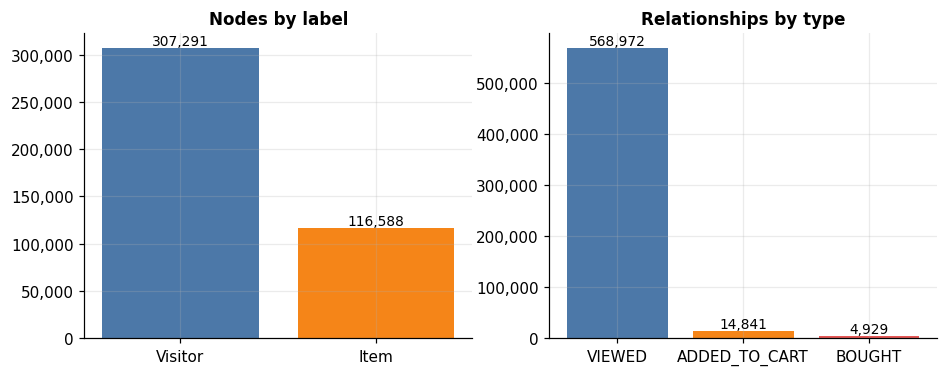

INSIGHT
- Graf berisi 423,879 simpul (307,291 Visitor + 116,588 Item) dan 588,742 relasi.
- Validasi impor: jumlah relasi (588,742) = jumlah event di CSV P1 (588,742). Tidak ada event yang hilang atau terduplikasi.
- Visitor lebih banyak daripada item (2.6 : 1). Ingat angka ini; ia menentukan proyeksi mana yang lebih murah (No. 6).
- Rata-rata derajat: 1.9 relasi per Visitor, 5.0 relasi per Item.


In [12]:
nodes, rels = graph_io.fetch_composition(driver, DB)
display(nodes.style.format({"total": "{:,}"}).hide(axis="index"))
display(rels.style.format({"total": "{:,}"}).hide(axis="index"))
viz.plot_composition(nodes, rels)
plt.show()

n_vis = int(nodes.set_index("label").loc["Visitor", "total"])
n_itm = int(nodes.set_index("label").loc["Item", "total"])
n_rel = int(rels["total"].sum())
assert n_rel == len(train), "jumlah relasi harus sama dengan jumlah event P1"
print("INSIGHT")
print(f"- Graf berisi {n_vis + n_itm:,} simpul ({n_vis:,} Visitor + {n_itm:,} Item) dan {n_rel:,} relasi.")
print(f"- Validasi impor: jumlah relasi ({n_rel:,}) = jumlah event di CSV P1 ({len(train):,}). Tidak ada event yang hilang atau terduplikasi.")
print(f"- Visitor lebih banyak daripada item ({n_vis / n_itm:.1f} : 1). Ingat angka ini; ia menentukan proyeksi mana yang lebih murah (No. 6).")
print(f"- Rata-rata derajat: {n_rel / n_vis:.1f} relasi per Visitor, {n_rel / n_itm:.1f} relasi per Item.")

### No. 4: VSM untuk simpul User

perhitungannya yaitu satu visitor adalah satu vektor, dimensinya seluruh item. pembobotan memakai: bobot relasi (`VIEWED` 1, `ADDED_TO_CART` 3, `BOUGHT` 5), TF `log(1 + bobot)`, IDF per item, lalu normalisasi L2 sehingga dot product sama dengan cosine

In [13]:
print(queries.INTERACTIONS.strip())
edges = graph_io.fetch_interactions(driver, DB)
inter = vsm.build_interactions(edges, config.REL_WEIGHTS)
print(f"\nBaris hasil query (visitor, item, tipe relasi) : {len(edges):,}")
print(f"Pasangan visitor-item unik (sel non-nol)      : {inter.matrix.nnz:,}")

MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitorId, i.itemId AS itemId, type(r) AS rel, count(r) AS n

Baris hasil query (visitor, item, tipe relasi) : 473,464
Pasangan visitor-item unik (sel non-nol)      : 457,960


In [15]:
def pick_focus(support: np.ndarray, low: int, high: int, seed: int) -> int:
    """Reproducible choice of a 'typical' row (neither a cold-start nor a bot) for the example plots."""
    pool = np.flatnonzero((support >= low) & (support <= high))
    return int(np.random.default_rng(seed).choice(pool if len(pool) else np.arange(len(support))))

user_vsm = vsm.build_vsm(inter, "user")
user_stats = vsm.describe_matrix(user_vsm.matrix)
norms = np.sqrt(np.asarray(user_vsm.matrix.multiply(user_vsm.matrix).sum(axis=1)).ravel())

print("KARAKTERISTIK VSM USER")
print(f"- Shape        : {user_vsm.matrix.shape[0]:,} baris (visitor) x {user_vsm.matrix.shape[1]:,} kolom (item)")
print(f"- Dimensi      : setiap visitor adalah vektor di R^{user_vsm.matrix.shape[1]:,}")
print(f"- Non-nol      : {user_stats['non_zeros']:,}  ->  sparsity {user_stats['sparsity_%']:.4f}%")
print(f"- Panjang baris: rata-rata {user_stats['mean_nnz_per_row']:.2f}, median {user_stats['median_nnz_per_row']:.0f}, maksimum {user_stats['max_nnz_per_row']:,} item berbeda")
print(f"- Memori       : {user_stats['sparse_memory_MB']:,.1f} MB (sparse)  vs  {user_stats['dense_memory_GB']:,.1f} GB jika dibuat dense")
print(f"- Cek normalisasi: norma tiap baris min {norms[norms > 0].min():.4f}, maks {norms.max():.4f} (harus 1)")

focus_user = pick_focus(user_vsm.support, 4, 8, config.SEED)
row = user_vsm.matrix[focus_user]
raw = inter.matrix[focus_user]
profile = pd.DataFrame({"itemId": inter.item_ids[row.indices], "bobot mentah": raw.toarray().ravel()[row.indices], "bobot tf-idf ternormalisasi": row.data})
print(f"\nContoh vektor: Visitor {inter.user_ids[focus_user]} (hanya {len(profile)} dari {user_vsm.matrix.shape[1]:,} komponen yang tidak nol)")
display(profile.sort_values("bobot tf-idf ternormalisasi", ascending=False))

KARAKTERISTIK VSM USER
- Shape        : 307,291 baris (visitor) x 116,588 kolom (item)
- Dimensi      : setiap visitor adalah vektor di R^116,588
- Non-nol      : 457,960  ->  sparsity 99.9987%
- Panjang baris: rata-rata 1.49, median 1, maksimum 1,318 item berbeda
- Memori       : 6.7 MB (sparse)  vs  286.6 GB jika dibuat dense
- Cek normalisasi: norma tiap baris min 1.0000, maks 1.0000 (harus 1)

Contoh vektor: Visitor 7950 (hanya 7 dari 116,588 komponen yang tidak nol)


,itemId,bobot mentah,bobot tf-idf ternormalisasi
6,460496,2.0000,0.4871
4,370510,2.0000,0.4602
5,376720,2.0000,0.4444
0,91526,1.0000,0.3073
1,200010,1.0000,0.3073
2,252862,1.0000,0.2903
3,253710,1.0000,0.2833


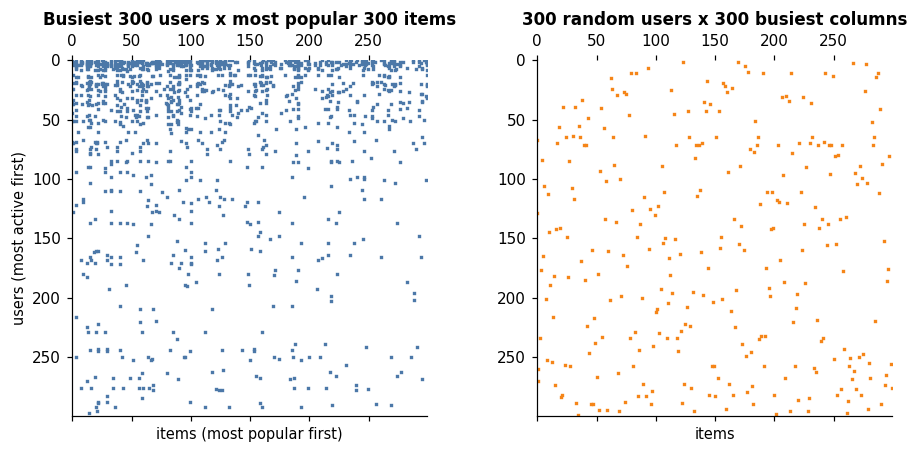

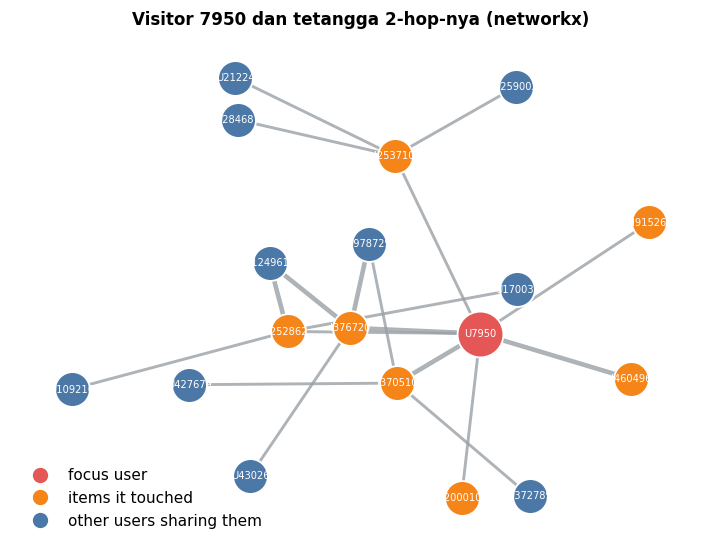

INSIGHT
- Matriks 99.999% kosong. Menyimpannya dense akan butuh 287 GB, sedangkan format sparse hanya 7 MB. Pilihan sparse bukan optimasi, melainkan syarat.
- Median visitor hanya menyentuh 1 item, sementara yang terpadat 1,318. Vektor user sangat pendek, jadi dua user hanya mirip jika kebetulan menyentuh item yang sama.
- Plot networkx: titik merah (fokus) terhubung ke item yang ia sentuh; titik hijau adalah user lain yang berbagi item tersebut. Itulah tetangga di *proyeksi user-user*.


In [16]:
viz.plot_density_block(inter.matrix)
plt.show()
graph = viz.ego_graph(inter, "user", focus_user)
viz.plot_ego(graph, "user", f"Visitor {inter.user_ids[focus_user]} dan tetangga 2-hop-nya (networkx)", "07_ego_user")
plt.show()
print("INSIGHT")
print(f"- Matriks {user_stats['sparsity_%']:.3f}% kosong. Menyimpannya dense akan butuh {user_stats['dense_memory_GB']:,.0f} GB, sedangkan format sparse hanya {user_stats['sparse_memory_MB']:,.0f} MB. Pilihan sparse bukan optimasi, melainkan syarat.")
print(f"- Median visitor hanya menyentuh {user_stats['median_nnz_per_row']:.0f} item, sementara yang terpadat {user_stats['max_nnz_per_row']:,}. Vektor user sangat pendek, jadi dua user hanya mirip jika kebetulan menyentuh item yang sama.")
print("- Plot networkx: titik merah (fokus) terhubung ke item yang ia sentuh; titik hijau adalah user lain yang berbagi item tersebut. Itulah tetangga di *proyeksi user-user*.")

### No. 5: VSM untuk simpul Item

Satu Item adalah satu vektor, dimensinya seluruh Visitor. Ini transpos matriks sebelumnya; IDF kini dihitung per visitor, sehingga visitor yang menyentuh banyak item (bot) ikut diredam.

KARAKTERISTIK VSM ITEM
- Shape        : 116,588 baris (item) x 307,291 kolom (visitor)
- Dimensi      : setiap item adalah vektor di R^307,291
- Non-nol      : 457,960  ->  sparsity 99.9987%
- Panjang baris: rata-rata 3.93, median 2, maksimum 330 visitor berbeda
- Memori       : 6.0 MB (sparse)  vs  286.6 GB jika dibuat dense


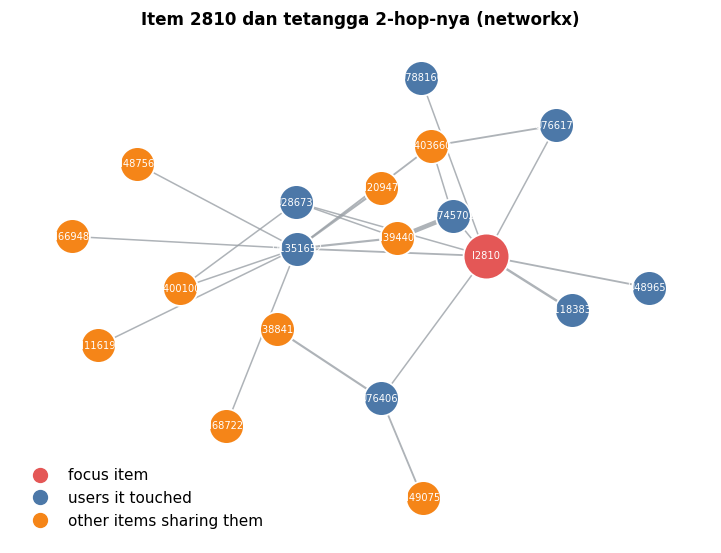

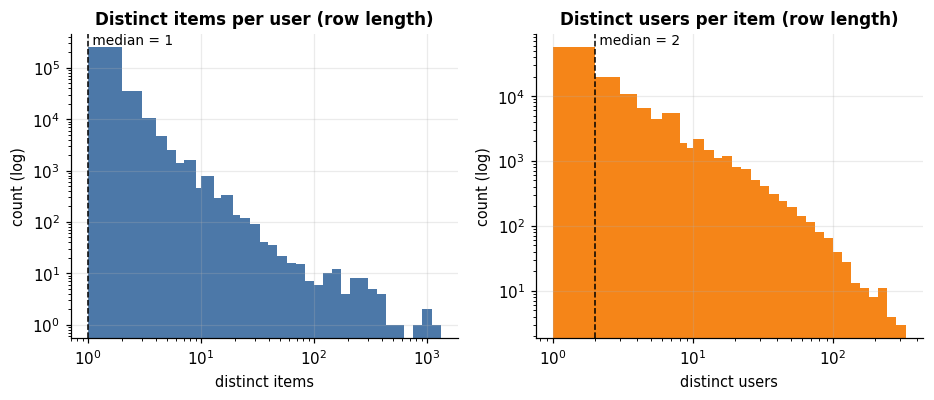

INSIGHT
- Jumlah non-nol identik (457,960) karena ini matriks yang sama, hanya ditranspos. Yang berubah adalah **bentuk**: (307291, 116588) menjadi (116588, 307291).
- Vektor item rata-rata 2.6x lebih padat daripada vektor user (3.9 vs 1.5 non-nol per baris).
  Vektor yang lebih padat berarti dua item lebih mudah berbagi dimensi, sehingga cosine antar item lebih stabil daripada antar user.
- Tetapi ekor panjangnya tetap ada: median item disentuh 2 visitor, item terpopuler 330 visitor.


In [17]:
item_vsm = vsm.build_vsm(inter, "item")
item_stats = vsm.describe_matrix(item_vsm.matrix)

print("KARAKTERISTIK VSM ITEM")
print(f"- Shape        : {item_vsm.matrix.shape[0]:,} baris (item) x {item_vsm.matrix.shape[1]:,} kolom (visitor)")
print(f"- Dimensi      : setiap item adalah vektor di R^{item_vsm.matrix.shape[1]:,}")
print(f"- Non-nol      : {item_stats['non_zeros']:,}  ->  sparsity {item_stats['sparsity_%']:.4f}%")
print(f"- Panjang baris: rata-rata {item_stats['mean_nnz_per_row']:.2f}, median {item_stats['median_nnz_per_row']:.0f}, maksimum {item_stats['max_nnz_per_row']:,} visitor berbeda")
print(f"- Memori       : {item_stats['sparse_memory_MB']:,.1f} MB (sparse)  vs  {item_stats['dense_memory_GB']:,.1f} GB jika dibuat dense")

focus_item = pick_focus(item_vsm.support, 8, 40, config.SEED)
graph = viz.ego_graph(inter, "item", focus_item)
viz.plot_ego(graph, "item", f"Item {inter.item_ids[focus_item]} dan tetangga 2-hop-nya (networkx)", "07_ego_item")
plt.show()
viz.plot_degree_distributions(inter)
plt.show()

print("INSIGHT")
print(f"- Jumlah non-nol identik ({item_stats['non_zeros']:,}) karena ini matriks yang sama, hanya ditranspos. Yang berubah adalah **bentuk**: {user_vsm.matrix.shape} menjadi {item_vsm.matrix.shape}.")
print(f"- Vektor item rata-rata {item_stats['mean_nnz_per_row'] / user_stats['mean_nnz_per_row']:.1f}x lebih padat daripada vektor user ({item_stats['mean_nnz_per_row']:.1f} vs {user_stats['mean_nnz_per_row']:.1f} non-nol per baris).")
print("  Vektor yang lebih padat berarti dua item lebih mudah berbagi dimensi, sehingga cosine antar item lebih stabil daripada antar user.")
print(f"- Tetapi ekor panjangnya tetap ada: median item disentuh {item_stats['median_nnz_per_row']:.0f} visitor, item terpopuler {item_stats['max_nnz_per_row']:,} visitor.")

### No. 6: Pemilihan proyeksi

In [18]:
capped = vsm.drop_heavy_users(inter, config.MAX_USER_ITEMS)
cost_raw, cost_cap = vsm.projection_cost(inter), vsm.projection_cost(capped)
removed_users = inter.shape[0] - capped.shape[0]
event_share = 1 - capped.matrix.sum() / inter.matrix.sum()

print(f"Visitor dikeluarkan (> {config.MAX_USER_ITEMS} item berbeda): {removed_users:,} dari {inter.shape[0]:,} ({removed_users / inter.shape[0]:.3%}), setara {event_share:.1%} dari total bobot interaksi")
cost_table = pd.DataFrame(
    {
        "tanpa batas": [cost_raw["user_projection_paths"], cost_raw["item_projection_paths"]],
        f"batas {config.MAX_USER_ITEMS} item/user": [cost_cap["user_projection_paths"], cost_cap["item_projection_paths"]],
    },
    index=["proyeksi user-user (2-path)", "proyeksi item-item (2-path)"],
)
cost_table["penurunan"] = cost_table.iloc[:, 0] / cost_table.iloc[:, 1]
display(cost_table.style.format({"tanpa batas": "{:,.0f}", f"batas {config.MAX_USER_ITEMS} item/user": "{:,.0f}", "penurunan": "{:,.1f}x"}))

comparison = pd.DataFrame(
    {
        "proyeksi user-user": [capped.shape[0], capped.shape[1], capped.matrix.nnz, cost_cap["user_projection_paths"]],
        "proyeksi item-item": [capped.shape[1], capped.shape[0], capped.matrix.nnz, cost_cap["item_projection_paths"]],
    },
    index=["simpul pada proyeksi", "dimensi vektor", "non-nol matriks asal", "2-path yang dienumerasi"],
)
display(comparison.style.format("{:,.0f}"))

Visitor dikeluarkan (> 100 item berbeda): 64 dari 307,291 (0.021%), setara 5.9% dari total bobot interaksi


,tanpa batas,batas 100 item/user,penurunan
proyeksi user-user (2-path),"4,712,224","4,403,517",1.1x
proyeksi item-item (2-path),"5,204,154","586,089",8.9x


,proyeksi user-user,proyeksi item-item
simpul pada proyeksi,"307,227","114,174"
dimensi vektor,"114,174","307,227"
non-nol matriks asal,"439,677","439,677"
2-path yang dienumerasi,"4,403,517","586,089"


In [19]:
truth = metrics.build_ground_truth(test, capped)
eligible = metrics.eligible_users(capped, truth, min_items=3, max_items=config.MAX_USER_ITEMS)
print("Statistik ground truth:")
for key, value in truth.stats.items():
    print(f"  {key:<40} {value:,.1f}")
print(f"\nUser layak dievaluasi (riwayat 3..{config.MAX_USER_ITEMS} item di P1, >= 1 item baru di P2): {len(eligible):,}")

recs = {
    "user": recommender.KNNRecommender(capped, "user", k=config.K_NEIGHBOURS, min_support=config.MIN_SUPPORT),
    "item": recommender.KNNRecommender(capped, "item", k=config.K_NEIGHBOURS, min_support=config.MIN_SUPPORT),
}
baseline = recommender.PopularityRecommender(capped)
models = {baseline.name: baseline, recs["user"].name: recs["user"], recs["item"].name: recs["item"]}

sample = np.random.default_rng(config.SEED + 1).choice(eligible, size=min(config.N_EVAL_USERS, len(eligible)), replace=False)
N = config.TOP_N
per_user, rows = {}, []
for name, model in models.items():
    started = time.perf_counter()
    per_user[name] = metrics.evaluate(model, capped, truth, sample, N)
    elapsed = time.perf_counter() - started
    row = {"method": name, "seconds": elapsed}
    for metric in (f"hit@{N}", f"ndcg@{N}"):
        lo, hi = metrics.bootstrap_ci(per_user[name][metric].to_numpy(), seed=config.SEED)
        row |= {metric: per_user[name][metric].mean(), f"{metric}_lo": lo, f"{metric}_hi": hi}
    rows.append(row)
summary_table = pd.DataFrame(rows).set_index("method")
display(summary_table)

Statistik ground truth:
  test_visitors                            183,106.0
  test_visitors_in_training_%              5.3
  test_items                               84,545.0
  test_items_in_training_catalogue_%       65.9
  visitors_with_new_relevant_items         6,593.0

User layak dievaluasi (riwayat 3..100 item di P1, >= 1 item baru di P2): 1,652


,seconds,hit@5,hit@5_lo,hit@5_hi,ndcg@5,ndcg@5_lo,ndcg@5_hi
method,,,,,,,
Popularity,109.8001,0.0033,0.0000,0.0101,0.0011,0.0000,0.0034
User-KNN (k=5),88.9994,0.0667,0.0400,0.1000,0.0283,0.0157,0.0433
Item-KNN (k=5),77.5424,0.0567,0.0300,0.0833,0.0227,0.0108,0.0373


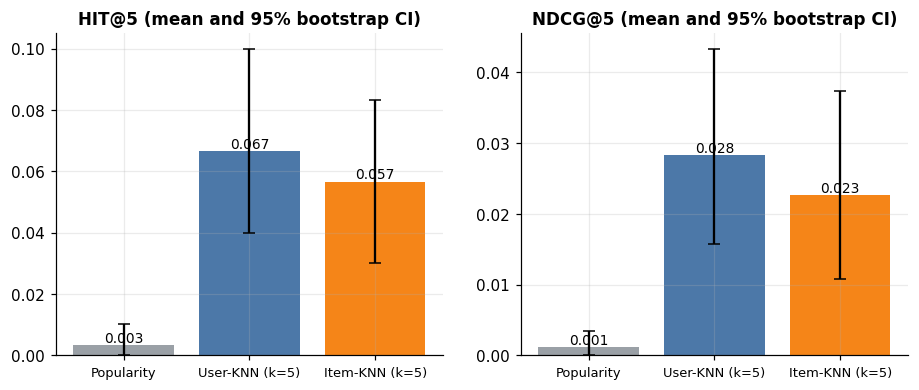

KESIMPULAN NO. 6
- Pemenang: PROYEKSI USER-USER -> proyeksi user lebih akurat (0.0283 vs 0.0227, selisih 20%) walau proyeksi item lebih murah.
- Simpul: proyeksi user memuat 307,227 simpul, proyeksi item 114,174. Proyeksi pada sisi yang lebih kecil menghasilkan graf yang lebih kecil.
- Biaya enumerasi 2-path (setelah batas bot): user-user 4,403,517 vs item-item 586,089.
- Pembatas bot menurunkan biaya proyeksi item 8.9x dan proyeksi user 1.1x, dengan hanya mengorbankan 0.021% visitor.
- User-KNN (k=5): NDCG@5 = 0.0283, 25.0x dibanding popularity (0.0011).
- Item-KNN (k=5): NDCG@5 = 0.0227, 20.0x dibanding popularity (0.0011).


In [20]:
def choose_projection(cost: dict, summary: pd.DataFrame, metric: str, tolerance: float = 0.05) -> tuple[str, str]:
    """Effectiveness first, if the two projections are within `tolerance`, the cheaper one wins."""
    cheaper = "item" if cost["item_projection_paths"] <= cost["user_projection_paths"] else "user"
    quality = {s: float(summary.loc[recs[s].name, metric]) for s in ("user", "item")}
    better = max(quality, key=quality.get)
    other = "item" if better == "user" else "user"
    gap = (quality[better] - quality[other]) / max(quality[better], 1e-12)
    if better == cheaper:
        return better, f"proyeksi {better} unggul di dua kriteria: {metric} lebih tinggi ({quality[better]:.4f} vs {quality[other]:.4f}) dan lebih murah."
    if gap > tolerance:
        return better, f"proyeksi {better} lebih akurat ({quality[better]:.4f} vs {quality[other]:.4f}, selisih {gap:.0%}) walau proyeksi {cheaper} lebih murah."
    return cheaper, f"akurasi kedua proyeksi setara (selisih {gap:.0%} < {tolerance:.0%}), jadi dipilih yang lebih murah: proyeksi {cheaper}."

PROJECTION, reason = choose_projection(cost_cap, summary_table, f"ndcg@{N}")
LABEL, KEY = ("Visitor", "visitorId") if PROJECTION == "user" else ("Item", "itemId")
viz.plot_metric_comparison(summary_table, N)
plt.show()

base = summary_table.loc[baseline.name, f"ndcg@{N}"]
print("KESIMPULAN NO. 6")
print(f"- Pemenang: PROYEKSI {PROJECTION.upper()}-{PROJECTION.upper()} -> {reason}")
print(f"- Simpul: proyeksi user memuat {capped.shape[0]:,} simpul, proyeksi item {capped.shape[1]:,}. Proyeksi pada sisi yang lebih kecil menghasilkan graf yang lebih kecil.")
print(f"- Biaya enumerasi 2-path (setelah batas bot): user-user {cost_cap['user_projection_paths']:,.0f} vs item-item {cost_cap['item_projection_paths']:,.0f}.")
print(f"- Pembatas bot menurunkan biaya proyeksi item {cost_table.iloc[1, 2]:,.1f}x dan proyeksi user {cost_table.iloc[0, 2]:,.1f}x, dengan hanya mengorbankan {removed_users / inter.shape[0]:.3%} visitor.")
for s in ("user", "item"):
    value = summary_table.loc[recs[s].name, f"ndcg@{N}"]
    print(f"- {recs[s].name}: NDCG@{N} = {value:.4f}, {'%.1fx' % (value / base) if base > 0 else 'n/a'} dibanding popularity ({base:.4f}).")

### No. 7: Similarity pada graf terproyeksi

Record acuan dipilih reproducible (seed dari NIM). Cosine antar baris VSM:

$$\cos(x, y) = \frac{x \cdot y}{\lVert x \rVert \, \lVert y \rVert}$$

MIN_SUPPORT membuang kandidat dengan data terlalu sedikit, karena cosine mudah bernilai 1,0 secara kebetulan.

In [23]:
model = recs[PROJECTION].vsm
low, high = (20, 100) if PROJECTION == "item" else (5, 30)
ref_row = pick_focus(model.support, low, high, config.SEED + 2)
ref_id = int(model.ids[ref_row])
print(f"Proyeksi terpilih : {PROJECTION}-{PROJECTION}   (label Neo4j: {LABEL})")
print(f"Record acuan      : {KEY} = {ref_id}  (terhubung ke {model.support[ref_row]} simpul lawan)")

neighbour_rows, neighbour_scores = vsm.top_k_neighbours(model, [ref_row], config.K_NEIGHBOURS, config.MIN_SUPPORT)[ref_row]
python_top5 = pd.DataFrame({KEY: model.ids[neighbour_rows], "cosine (tf-idf)": neighbour_scores})
python_top5.index = range(1, len(python_top5) + 1)
display(python_top5)

Proyeksi terpilih : user-user   (label Neo4j: Visitor)
Record acuan      : visitorId = 487785  (terhubung ke 9 simpul lawan)


,visitorId,cosine (tf-idf)
1,832514,0.5385
2,92704,0.4720
3,496078,0.4116
4,920524,0.4112
5,1101808,0.4107


(a) Top-5 lewat Cypher. Cosine biner common / sqrt(nRef * nOther) dihitung murni di Cypher dan dibandingkan dengan hasil Python sebagai uji silang

In [22]:
print(queries.COSINE_CROSS_CHECK[PROJECTION].strip())
cypher_top5 = graph_io.run_df(driver, queries.COSINE_CROSS_CHECK[PROJECTION], DB, ref=ref_id)

binary_inter = vsm.Interactions(vsm.binary(inter.matrix), inter.user_ids, inter.item_ids)
binary_vsm = vsm.build_vsm(binary_inter, PROJECTION, tfidf=False)
bin_row = int(np.searchsorted(binary_vsm.ids, ref_id))
bin_rows, bin_scores = vsm.top_k_neighbours(binary_vsm, [bin_row], 5, min_support=1)[bin_row]
python_binary = pd.DataFrame({KEY: binary_vsm.ids[bin_rows], "cosine_python": bin_scores})

check = cypher_top5.rename(columns={"cosine": "cosine_cypher"}).merge(python_binary, on=KEY, how="outer")
display(check)
both = check.dropna(subset=["cosine_cypher", "cosine_python"])
print("UJI SILANG")
print(f"- Simpul yang muncul di kedua hasil: {len(both)} dari {len(check)}.")
if len(both):
    print(f"- Selisih cosine terbesar pada simpul yang sama: {np.abs(both['cosine_cypher'] - both['cosine_python']).max():.2e} (selisih ~0 berarti Python dan Cypher sepakat).")
print("- Jika ada simpul yang hanya muncul di satu sisi, penyebabnya hampir selalu skor yang kembar (tie) di batas peringkat ke-5.")

MATCH (ref:Visitor {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH ref, collect(DISTINCT i) AS refItems
WITH ref, refItems, size(refItems) AS nRef
UNWIND refItems AS i
MATCH (i)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(other:Visitor)
WHERE other <> ref
WITH nRef, other, count(DISTINCT i) AS common
MATCH (other)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(j:Item)
WITH nRef, other, common, count(DISTINCT j) AS nOther
RETURN other.visitorId AS visitorId, common, nOther,
       toFloat(common) / sqrt(toFloat(nRef) * nOther) AS cosine
ORDER BY cosine DESC, common DESC
LIMIT 5


,visitorId,common,nOther,cosine_cypher,cosine_python
0,3470,2,2,0.4714,0.4714
1,92704,4,8,0.4714,0.4714
2,569700,2,2,0.4714,0.4714
3,918669,2,2,0.4714,0.4714
4,1082553,2,2,0.4714,0.4714


UJI SILANG
- Simpul yang muncul di kedua hasil: 5 dari 5.
- Selisih cosine terbesar pada simpul yang sama: 5.55e-17 (selisih ~0 berarti Python dan Cypher sepakat).
- Jika ada simpul yang hanya muncul di satu sisi, penyebabnya hampir selalu skor yang kembar (tie) di batas peringkat ke-5.


**(b) Menulis similarity ke graf.** Relasi `SIMILAR_TO {score, rank}` ditulis untuk 1.000 simpul terpadat plus simpul acuan. `MERGE` bersifat idempoten.

In [24]:
N_WRITE = 1_000
write_rows = np.union1d(np.argsort(-model.support, kind="stable")[:N_WRITE], [ref_row])
pairs = recommender.similarity_pairs(model, write_rows, config.K_NEIGHBOURS, config.MIN_SUPPORT)

before_table = graph_io.run_df(driver, queries.BEFORE_TABLE[PROJECTION], DB, ref=ref_id)
graph_io.clear_similarity(driver, DB)
count_before = int(graph_io.run_df(driver, queries.SIMILARITY_COUNT, DB).iloc[0, 0])

print(queries.write_similarity(LABEL, KEY).strip())
written = graph_io.write_similarity(driver, DB, LABEL, KEY, pairs)
count_after = int(graph_io.run_df(driver, queries.SIMILARITY_COUNT, DB).iloc[0, 0])
print(f"\nRelasi SIMILAR_TO sebelum: {count_before:,}   sesudah: {count_after:,}   (ditulis {written:,} baris)")

print("\nQuery pembacaan 5 teratas dari graf:")
print(queries.top_similar(LABEL, KEY).strip())
stored_top5 = graph_io.run_df(driver, queries.top_similar(LABEL, KEY), DB, ref=ref_id)
display(stored_top5)
assert list(stored_top5[KEY]) == list(python_top5[KEY]), "isi graf harus sama dengan hasil Python"
print("Pemeriksaan: lima tetangga yang tersimpan di Neo4j identik dengan hasil Python.")

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR_TO` does not exist in database `retailrocket`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=13, offset=12>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 12, 'line': 1, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS similar_to_relationships'


UNWIND $rows AS row
MATCH (a:Visitor {visitorId: row.source})
MATCH (b:Visitor {visitorId: row.target})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.rank = row.rank, s.metric = 'cosine'

Relasi SIMILAR_TO sebelum: 0   sesudah: 4,952   (ditulis 4,952 baris)

Query pembacaan 5 teratas dari graf:
MATCH (ref:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(other:Visitor)
RETURN other.visitorId AS visitorId, s.score AS similarity, s.rank AS rank
ORDER BY similarity DESC
LIMIT 5


,visitorId,similarity,rank
0,832514,0.5385,1
1,92704,0.4720,2
2,496078,0.4116,3
3,920524,0.4112,4
4,1101808,0.4107,5


Pemeriksaan: lima tetangga yang tersimpan di Neo4j identik dengan hasil Python.


### No. 8: Graf sebelum dan sesudah

In [25]:
print(f":param ref => {ref_id};\n")
print("-- SEBELUM: simpul acuan dan relasi interaksi mentahnya, belum ada relasi kemiripan")
print((queries.BEFORE_ITEM if PROJECTION == "item" else queries.BEFORE_USER).strip())
print("\n-- SESUDAH: simpul acuan dengan 5 relasi SIMILAR_TO berskor")
print(queries.similarity_subgraph(LABEL, KEY).strip())

:param ref => 487785;

-- SEBELUM: simpul acuan dan relasi interaksi mentahnya, belum ada relasi kemiripan
MATCH p = (v:Visitor {visitorId: $ref})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN p
LIMIT 25

-- SESUDAH: simpul acuan dengan 5 relasi SIMILAR_TO berskor
MATCH p = (ref:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(other:Visitor)
RETURN p
ORDER BY s.score DESC
LIMIT 5


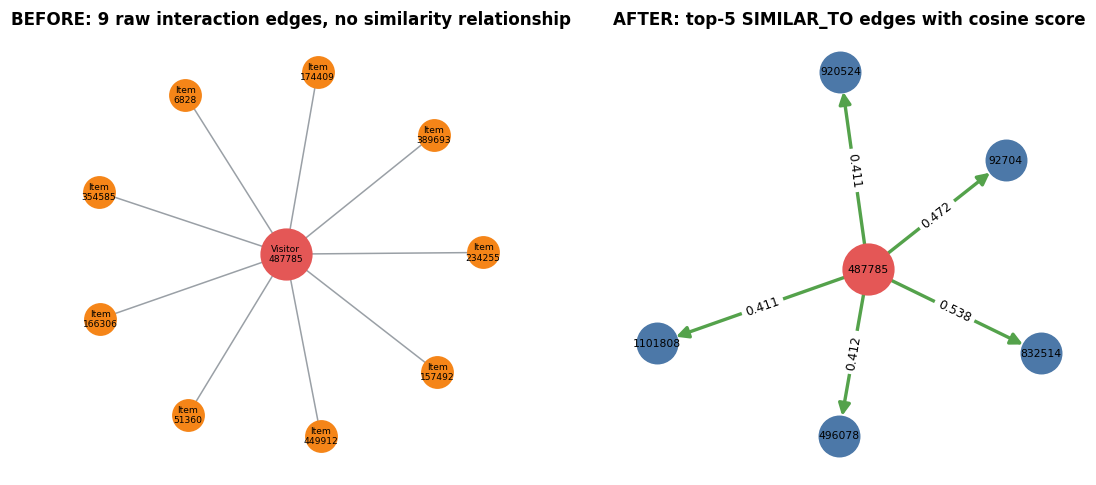

INSIGHT
- Sebelum: simpul acuan hanya terhubung lewat relasi interaksi mentah (19 ditampilkan), dan jumlah relasi SIMILAR_TO = 0.
- Sesudah: 4,952 relasi SIMILAR_TO tersimpan; simpul acuan kini punya 5 tetangga berskor (0.411 sampai 0.538).
- Tipe relasi di graf sekarang: ADDED_TO_CART, BOUGHT, SIMILAR_TO, VIEWED. Graf **diperkaya**: kemiripan yang tadinya harus dihitung ulang setiap kali kini cukup dibaca dengan satu `MATCH`.
- Skor menurun mulus dari tetangga 1 ke 5; selisih yang tajam di antaranya menandakan satu tetangga yang jauh lebih dekat daripada sisanya.


In [26]:
pairs_after = graph_io.run_df(driver, queries.similarity_edges(LABEL, KEY), DB, ref=ref_id)
viz.plot_before_after(before_table, pairs_after, PROJECTION, ref_id)
plt.show()

rel_types = sorted(set(rels["relationship"]) | {"SIMILAR_TO"})
print("INSIGHT")
print(f"- Sebelum: simpul acuan hanya terhubung lewat relasi interaksi mentah ({len(before_table)} ditampilkan), dan jumlah relasi SIMILAR_TO = {count_before}.")
print(f"- Sesudah: {count_after:,} relasi SIMILAR_TO tersimpan; simpul acuan kini punya {len(pairs_after)} tetangga berskor ({pairs_after['score'].min():.3f} sampai {pairs_after['score'].max():.3f}).")
print(f"- Tipe relasi di graf sekarang: {', '.join(rel_types)}. Graf **diperkaya**: kemiripan yang tadinya harus dihitung ulang setiap kali kini cukup dibaca dengan satu `MATCH`.")
print("- Skor menurun mulus dari tetangga 1 ke 5; selisih yang tajam di antaranya menandakan satu tetangga yang jauh lebih dekat daripada sisanya.")

## 2.2 Analytics

### No. 1: Rekomendasi KNN untuk user acak

usernyaa dipilih dengan dari user yang punya riwayat di P1 dan minimal satu item baru di P2, sehingga hasilnya reproducible

In [27]:
rng = np.random.default_rng(config.SEED)
user_row = int(rng.choice(eligible))
user_id = int(capped.user_ids[user_row])

history = edges[edges["visitorId"] == user_id].pivot_table(index="itemId", columns="rel", values="n", aggfunc="sum", fill_value=0)
history["bobot"] = capped.matrix[user_row].toarray().ravel()[capped.matrix[user_row].indices]
print(f"User terpilih: visitorId = {user_id}  (baris ke-{user_row} dari {capped.shape[0]:,}; dipilih dari {len(eligible):,} user layak)")
print(f"Riwayat P1: {len(history)} item berbeda")
display(history.sort_values("bobot", ascending=False))

relevant_items = sorted(int(capped.item_ids[c]) for c in truth.relevant[user_row])
print(f"Kunci jawaban (item baru yang dikunjungi user ini di P2): {relevant_items}")

User terpilih: visitorId = 9535  (baris ke-2115 dari 307,227; dipilih dari 1,652 user layak)
Riwayat P1: 41 item berbeda


rel,VIEWED,bobot
itemId,,
235655,2,2.0000
230977,2,2.0000
237486,1,1.0000
262844,1,1.0000
268842,1,1.0000
278730,1,1.0000
282940,1,1.0000
286482,1,1.0000
290449,1,1.0000


Kunci jawaban (item baru yang dikunjungi user ini di P2): [869, 1978, 6153, 8395, 9025, 9223, 16915, 26032, 26979, 27516, 32381, 45735, 49914, 66187, 71060, 77955, 90835, 90977, 104342, 118199, 118551, 119064, 127631, 128396, 135591, 137454, 141050, 142624, 146781, 149308, 155802, 159956, 162312, 164344, 169594, 172166, 176106, 179208, 181050, 186295, 188177, 189614, 206792, 212290, 227161, 230911, 231216, 234808, 235068, 245501, 249152, 251807, 252593, 254418, 255737, 256619, 258457, 261035, 269953, 276270, 276494, 278041, 285729, 294307, 301324, 305496, 307883, 308309, 314073, 315487, 323278, 330090, 332018, 336708, 338411, 342507, 350399, 360344, 368187, 371479, 375444, 386859, 386899, 387318, 398404, 399069, 427900, 428805, 430546, 433625, 438322, 455722, 459186]


(a) Skrip KNN User-based: skor item = Σ similarity tetangga x kekuatan interaksinya. Item-based: skor = Σ bobot seed x similarity item tetangga. item yang sudah dilihat tidak direkomendasikan

In [28]:
print(inspect.getsource(recommender.KNNRecommender))
print(inspect.getsource(vsm.top_k_neighbours))

class KNNRecommender:
    """User-based or item-based KNN, depending on the projection (`space`).

    user space: find the k most similar visitors, then score every item they touched by
                sum(similarity * their interaction strength).
    item space: for each item the visitor already touched (the "seeds", strongest first),
                find its k most similar items and accumulate similarity * seed strength.
    Items the visitor has already seen are never recommended.
    """

    def __init__(self, inter: Interactions, space: str, k: int = 5, min_support: int = 3, tfidf: bool = True, max_seeds: int = 20):
        self.inter, self.space, self.k = inter, space, k
        self.min_support, self.max_seeds = min_support, max_seeds
        self.tf = log_tf(inter)
        self.vsm: VSM = build_vsm(inter, space, tfidf)
        self.fallback = PopularityRecommender(inter)
        self.name = f"{space.capitalize()}-KNN (k={k})"
        self.last_neighbours = pd.DataFrame()

   

(b) Tiga item yang diiklanka untuk k = 5 adalah tiga teratas dari daftar top-5.

In [29]:
other = "item" if PROJECTION == "user" else "user"
alt_top = recs[other].recommend(user_row, N)
top5 = recs[PROJECTION].recommend(user_row, N)
advertised = top5.head(config.N_ADVERTISED)

print(f"3 ITEM YANG DIIKLANKAN ({recs[PROJECTION].name}) untuk visitor {user_id}")
display(advertised.set_index("rank"))
print(f"\nDaftar penuh top-{N}:")
display(top5.set_index("rank"))
print(f"Pembanding ({recs[other].name}): top-{N} = {alt_top['itemId'].tolist()}")

print("\nDasar rekomendasi (k = 5 tetangga):")
display(recs[PROJECTION].last_neighbours.head(25))

3 ITEM YANG DIIKLANKAN (User-KNN (k=5)) untuk visitor 9535


,itemId,score,supporters,source
rank,,,,
1,310434,0.0811,1,knn
2,377588,0.0811,1,knn
3,429571,0.0811,1,knn



Daftar penuh top-5:


,itemId,score,supporters,source
rank,,,,
1,310434,0.0811,1,knn
2,377588,0.0811,1,knn
3,429571,0.0811,1,knn
4,10952,0.0636,1,knn
5,12520,0.0636,1,knn


Pembanding (Item-KNN (k=5)): top-5 = [310434, 108561, 309778, 370653, 257040]

Dasar rekomendasi (k = 5 tetangga):


,visitorId,cosine,items_touched
0,1156298,0.1170,4
1,507366,0.0918,3
2,894886,0.0880,3
3,700540,0.0874,3
4,1076597,0.0872,4


In [30]:
print("INSIGHT")
filled = (top5["source"] != "knn").sum()
print(f"- Skor tiap item berasal dari tetangga: kolom 'supporters' menunjukkan berapa dari {config.K_NEIGHBOURS} tetangga yang mendukung item itu. Item dengan supporters lebih tinggi lebih dapat dipercaya.")
print(f"- {len(top5) - filled} dari {len(top5)} item berasal dari KNN, {filled} diisi popularitas." + (" Tetangga user ini sedikit, jadi KNN tidak cukup mengisi daftar." if filled else ""))
overlap = set(top5["itemId"]) & set(alt_top["itemId"])
print(f"- Kedua proyeksi sepakat pada {len(overlap)} dari {N} item. Kesepakatan tinggi = rekomendasi yang kokoh; rendah = tiap proyeksi menangkap sinyal berbeda.")

INSIGHT
- Skor tiap item berasal dari tetangga: kolom 'supporters' menunjukkan berapa dari 5 tetangga yang mendukung item itu. Item dengan supporters lebih tinggi lebih dapat dipercaya.
- 5 dari 5 item berasal dari KNN, 0 diisi popularitas.
- Kedua proyeksi sepakat pada 1 dari 5 item. Kesepakatan tinggi = rekomendasi yang kokoh; rendah = tiap proyeksi menangkap sinyal berbeda.


### No. 2: Hit@5 dan NDCG@5

Relevan = item yang disentuh di P2 dan belum pernah dilihat di P1.

$$\mathrm{DCG@N} = \sum_{i=1}^{N} \frac{rel_i}{\log_2(i+1)} \qquad \mathrm{NDCG@N} = \frac{\mathrm{DCG@N}}{\mathrm{IDCG@N}}$$

Hit@N bernilai 1 jika ada item relevan di N teratas.

In [31]:
ranked = [capped.item_index[int(i)] for i in top5["itemId"]]
relevant = truth.relevant[user_row]
rel_flags = [int(c in relevant) for c in ranked]

steps = pd.DataFrame(
    {
        "rank": range(1, len(ranked) + 1),
        "itemId": top5["itemId"].to_numpy(),
        "relevant": rel_flags,
        "1 / log2(rank + 1)": [1 / np.log2(i + 1) for i in range(1, len(ranked) + 1)],
    }
)
steps["kontribusi DCG"] = steps["relevant"] * steps["1 / log2(rank + 1)"]
display(steps.set_index("rank"))

n_ideal = min(N, len(relevant))
dcg_value = steps["kontribusi DCG"].sum()
idcg_value = sum(1 / np.log2(i + 1) for i in range(1, n_ideal + 1))
hit5, ndcg5 = metrics.hit_at_n(ranked, relevant, N), metrics.ndcg_at_n(ranked, relevant, N)
assert abs(ndcg5 - dcg_value / idcg_value) < 1e-12

print(f"Jumlah item relevan user ini : {len(relevant)}")
print(f"DCG@{N}  = {dcg_value:.4f}")
print(f"IDCG@{N} = {idcg_value:.4f}   (daftar ideal berisi {n_ideal} item relevan di peringkat teratas)")
print(f"\n>>> Hit@{N}  = {hit5:.0f}")
print(f">>> NDCG@{N} = {ndcg5:.4f}")
print(f"(Untuk 3 item iklan saja: Hit@3 = {metrics.hit_at_n(ranked, relevant, 3):.0f}, NDCG@3 = {metrics.ndcg_at_n(ranked, relevant, 3):.4f})")
if hit5 == 0:
    print("\nCATATAN: Hit@5 = 0 pada satu user bukan bukti model gagal. Satu user hanya punya sedikit item relevan di antara ribuan kandidat,")
    print("sehingga hasil biner ini sangat bergantung pada keberuntungan. Karena itu kesimpulan diambil dari evaluasi sampel user di bawah.")
else:
    print("\nCATATAN: model menemukan item relevan untuk user ini. Satu user tetap hanya satu sampel, jadi lihat evaluasi sampel di bawah untuk kesimpulan umum.")

,itemId,relevant,1 / log2(rank + 1),kontribusi DCG
rank,,,,
1,310434,0,1.0000,0.0000
2,377588,0,0.6309,0.0000
3,429571,0,0.5000,0.0000
4,10952,0,0.4307,0.0000
5,12520,0,0.3869,0.0000


Jumlah item relevan user ini : 93
DCG@5  = 0.0000
IDCG@5 = 2.9485   (daftar ideal berisi 5 item relevan di peringkat teratas)

>>> Hit@5  = 0
>>> NDCG@5 = 0.0000
(Untuk 3 item iklan saja: Hit@3 = 0, NDCG@3 = 0.0000)

CATATAN: Hit@5 = 0 pada satu user bukan bukti model gagal. Satu user hanya punya sedikit item relevan di antara ribuan kandidat,
sehingga hasil biner ini sangat bergantung pada keberuntungan. Karena itu kesimpulan diambil dari evaluasi sampel user di bawah.


In [32]:
chosen = per_user[recs[PROJECTION].name]
print(f"EVALUASI PADA {len(sample)} USER ACAK (seed = NIM + 1), data yang sama dengan No. 6")
display(summary_table.drop(columns=["seconds"]).style.format("{:.4f}"))
print("INSIGHT")
print(f"- {recs[PROJECTION].name}: Hit@{N} = {chosen[f'hit@{N}'].mean():.1%} dan NDCG@{N} = {chosen[f'ndcg@{N}'].mean():.4f} (rata-rata pada sampel).")
base_hit = per_user[baseline.name][f"hit@{N}"].mean()
if base_hit > 0:
    print(f"- Dibanding baseline popularity ({base_hit:.1%}), KNN {chosen[f'hit@{N}'].mean() / base_hit:.1f}x lebih sering menemukan item relevan.")
else:
    print("- Baseline popularity tidak menemukan satu pun item relevan pada sampel ini, sedangkan KNN menemukannya.")
print(f"- {(chosen[f'ndcg@{N}'] > 0).mean():.1%} user mendapat setidaknya satu item relevan di top-{N}; sisanya Hit = 0, wajar untuk katalog e-commerce yang sangat luas.")
print(f"- Nilai mutlak tampak kecil karena (1) hanya item BARU yang dihitung benar, (2) {100 - truth.stats['test_items_in_training_catalogue_%']:.0f}% item di P2 tidak ada di katalog P1, dan (3) setiap user hanya punya beberapa item relevan di antara ribuan kandidat.")
print("- Interval kepercayaan 95% (bootstrap) pada grafik di No. 6 menunjukkan apakah selisih antar metode nyata atau hanya noise sampel.")

EVALUASI PADA 300 USER ACAK (seed = NIM + 1), data yang sama dengan No. 6


,hit@5,hit@5_lo,hit@5_hi,ndcg@5,ndcg@5_lo,ndcg@5_hi
method,,,,,,
Popularity,0.0033,0.0000,0.0101,0.0011,0.0000,0.0034
User-KNN (k=5),0.0667,0.0400,0.1000,0.0283,0.0157,0.0433
Item-KNN (k=5),0.0567,0.0300,0.0833,0.0227,0.0108,0.0373


INSIGHT
- User-KNN (k=5): Hit@5 = 6.7% dan NDCG@5 = 0.0283 (rata-rata pada sampel).
- Dibanding baseline popularity (0.3%), KNN 20.0x lebih sering menemukan item relevan.
- 6.7% user mendapat setidaknya satu item relevan di top-5; sisanya Hit = 0, wajar untuk katalog e-commerce yang sangat luas.
- Nilai mutlak tampak kecil karena (1) hanya item BARU yang dihitung benar, (2) 34% item di P2 tidak ada di katalog P1, dan (3) setiap user hanya punya beberapa item relevan di antara ribuan kandidat.
- Interval kepercayaan 95% (bootstrap) pada grafik di No. 6 menunjukkan apakah selisih antar metode nyata atau hanya noise sampel.


## 3. Ringkasan jawaban

In [36]:
print(f"Nama / NIM / Kelas : {config.STUDENT['name']} / {config.STUDENT['nim']} / {config.STUDENT['class']}")
print(f"Formulir           : mulai = {first_ts} | selesai = {last_ts}  (UNIX timestamp, ms)")
print(f"P1 / P2            : {config.PERIOD_P1[0][:10]} s.d. {config.PERIOD_P1[1][:10]}  /  {config.PERIOD_P2[0][:10]} s.d. {config.PERIOD_P2[1][:10]}")
print(f"Graf training      : {n_vis:,} Visitor, {n_itm:,} Item, {n_rel:,} relasi")
print(f"Vektor user        : {user_vsm.matrix.shape}, sparsity {user_stats['sparsity_%']:.3f}%")
print(f"Vektor item        : {item_vsm.matrix.shape}, sparsity {item_stats['sparsity_%']:.3f}%")
print(f"Proyeksi terpilih  : {PROJECTION}-{PROJECTION}  ({reason})")
print(f"Record acuan       : {KEY} = {ref_id}; {count_after:,} relasi SIMILAR_TO ditulis")
print(f"User acak (KNN)    : visitorId = {user_id}; 3 item iklan = {advertised['itemId'].tolist()}")
print(f"Hit@{N} / NDCG@{N}     : {hit5:.0f} / {ndcg5:.4f}  (rata-rata sampel: {chosen[f'hit@{N}'].mean():.3f} / {chosen[f'ndcg@{N}'].mean():.4f})")

Nama / NIM / Kelas : Nazril Ravi Pratama / 24031554129 / International 24
Formulir           : mulai = 1430622004384 | selesai = 1442545187788  (UNIX timestamp, ms)
P1 / P2            : 2015-06-15 s.d. 2015-07-12  /  2015-07-13 s.d. 2015-07-26
Graf training      : 307,291 Visitor, 116,588 Item, 588,742 relasi
Vektor user        : (307291, 116588), sparsity 99.999%
Vektor item        : (116588, 307291), sparsity 99.999%
Proyeksi terpilih  : user-user  (proyeksi user lebih akurat (0.0283 vs 0.0227, selisih 20%) walau proyeksi item lebih murah.)
Record acuan       : visitorId = 487785; 4,952 relasi SIMILAR_TO ditulis
User acak (KNN)    : visitorId = 9535; 3 item iklan = [310434, 377588, 429571]
Hit@5 / NDCG@5     : 0 / 0.0000  (rata-rata sampel: 0.067 / 0.0283)


In [ ]:
driver.close()
print("Koneksi Neo4j ditutup.")